# code_177 · Counterfactual recourse sensitivity and transport

**Book:** section 33.5. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_33_GUIDE.md), [execution evidence](../CHAPTER_33_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_177).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Treatments, estimands, observed versus simulator-only outcomes, fitting roles and independent assessment are declared below. Generated interventions do not establish causal identification from arbitrary operational logs or validate an individual counterfactual.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=6477;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 6477


<a id="structural-counterfactual-and-inverse-scenario"></a>
 ## A changed prediction is not an identified action effect
 HiddenUaffects both loadL=2+0.8 U+noise and deteriorationY=0.5 L+1.2 U+noise. Fit an observational load-only regression on 3,000 source records. For a fixed eligible building, ask for a one-unit deterioration reduction. The predictor recommends a load decrease using its observational slope. In the declared structural model, changing load holds the combined exogenous residual Y−0.5 Lfixed, so the true individual counterfactual change is 0.5 times the load change. That equation is known here only because we wrote the simulator. The latentUand outcome noise cannot be separately recovered from this residual. Restrict feasible load reductions to 0.6 and a minimum remaining load 0.7; the true action needed for one-unit improvement can be infeasible. Separately invert a simply supported beam's midpoint-load equation under fixed known E,Iand span; matching a deflection target is not evidence about failure risk.


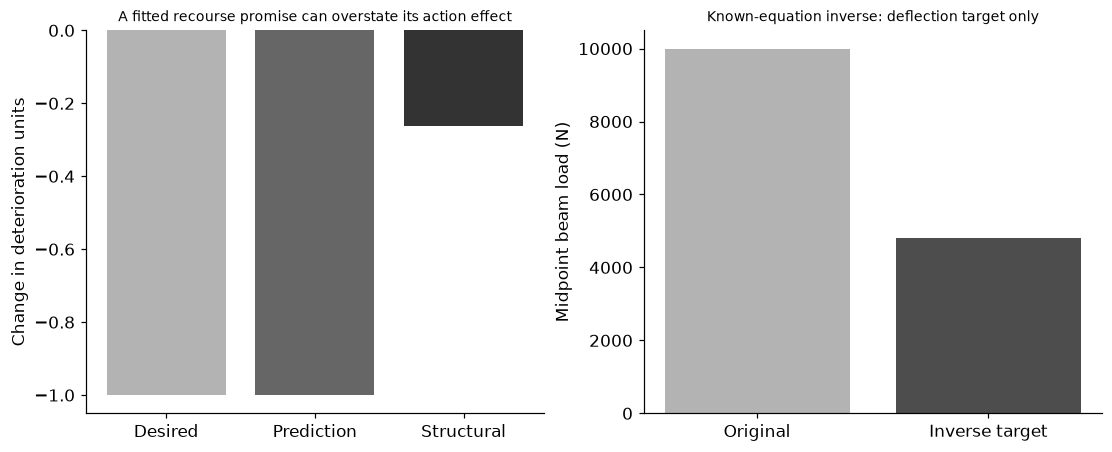

In [2]:
U=rng.normal(size=3000);L=2+.8*U+rng.normal(0,.2,3000);Y=.5*L+1.2*U+rng.normal(0,.2,3000);design=np.column_stack([np.ones(3000),L]);beta=np.linalg.lstsq(design,Y,rcond=None)[0];unit=int(np.flatnonzero(L>2.5)[0]);desired=-1.;proposed_delta=desired/beta[1];applied_delta=max(proposed_delta,-.6,.7-L[unit]);residual=Y[unit]-.5*L[unit];counterfactual=.5*(L[unit]+applied_delta)+residual;predicted_change=beta[1]*applied_delta;actual_change=counterfactual-Y[unit];needed=desired/.5
E=200e9;I=8e-6;span=4.;load_N=10000.;deflection_mm=load_N*span**3/(48*E*I)*1000;target_mm=4.;inverse_load=target_mm/1000*48*E*I/span**3;recovered_mm=inverse_load*span**3/(48*E*I)*1000
assert abs(applied_delta)<=.6+1e-12 and L[unit]+applied_delta>=.7;np.testing.assert_allclose(actual_change,.5*applied_delta);np.testing.assert_allclose(recovered_mm,target_mm)
RESULTS.update(source_buildings=3000,observational_load_slope=float(beta[1]),declared_structural_load_effect=.5,unit_index=unit,unit_observed_load=float(L[unit]),desired_outcome_change=desired,recourse_proposed_load_change=float(proposed_delta),feasible_applied_load_change=float(applied_delta),prediction_change=float(predicted_change),structural_counterfactual_change=float(actual_change),required_true_load_change=needed,true_target_feasible=bool(abs(needed)<=.6 and L[unit]+needed>=.7),beam={'E_Pa':E,'I_m4':I,'span_m':span,'original_load_N':load_N,'original_deflection_mm':deflection_mm,'target_deflection_mm':target_mm,'inverse_load_N':inverse_load,'verified_deflection_mm':recovered_mm},individual_exogenous_residual_held_fixed=True)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[desired,predicted_change,actual_change],color=['.7','.4','.2']);axes[0].set(xticks=range(3),xticklabels=['Desired','Prediction','Structural'],ylabel='Change in deterioration units',title='A fitted recourse promise can overstate its action effect');axes[1].bar(range(2),[load_N,inverse_load],color=['.7','.3']);axes[1].set(xticks=[0,1],xticklabels=['Original','Inverse target'],ylabel='Midpoint beam load (N)',title='Known-equation inverse: deflection target only');plt.show()


<a id="sensitivity-and-target-settings"></a>
 ## State what an unobserved bias and a new setting could change
 In a linear hidden-confounder sensitivity model, the omitted-variable bias is gamma×Cov(U,L)/Var(L). Treat covariance 0.8 as an explicit untestable sensitivity assumption, not an estimate recovered fromL,Y. Vary gamma 0 to 2 while keeping the observed slope and variance fixed. For transport, generate a separate binary-modifier maintenance study: source high-load prevalence 0.2 and target prevalence 0.8. Randomized source treatment supports an interaction fit. Standardizing its conditional effects to target covariates can correct the population mix only if the response mechanism is invariant. Assess independent target outcomes under both the unchanged mechanism and a changed high-load treatment response. Target covariates may supply standardization weights; target outcomes are final diagnostics only.


,setting,target_high_load_fraction,naive_source_average_effect,target_standardized_source_effect,true_target_effect,independent_randomized_target_difference
0,Changed mix,0.7995,-0.299994,-0.586887,-0.59975,-0.597517
1,Changed response,0.7995,-0.299994,-0.586887,0.03985,0.052741


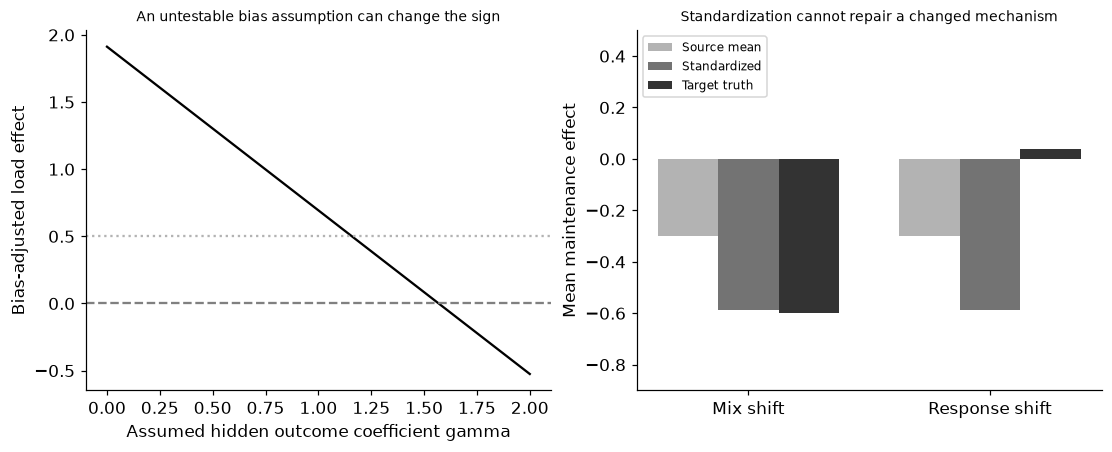

In [3]:
gamma_grid=np.linspace(0,2,41);assumed_cov=.8;sensitive=beta[1]-gamma_grid*assumed_cov/L.var(ddof=1)
def study(n,gr,prevalence,changed=False):
    z=(gr.random(n)<prevalence).astype(int);a=(gr.random(n)<.5).astype(int);tau=np.where(z,.1 if changed else -.7,-.2);y=1+.3*z+a*tau+gr.normal(0,.3,n);return z,a,y,tau
z,a,y,tau=study(4000,np.random.default_rng(SEED+100),.2);D=np.column_stack([np.ones(4000),z,a,z*a]);coef=np.linalg.lstsq(D,y,rcond=None)[0];source_effect=float(np.mean(coef[2]+coef[3]*z));transport=[]
for setting,changed in [('Changed mix',False),('Changed response',True)]:
    fz,fa,fy,ftau=study(2000,np.random.default_rng(SEED+200),.8,changed);predicted=float(np.mean(coef[2]+coef[3]*fz));transport.append({'setting':setting,'target_high_load_fraction':float(fz.mean()),'naive_source_average_effect':source_effect,'target_standardized_source_effect':predicted,'true_target_effect':float(ftau.mean()),'independent_randomized_target_difference':float(fy[fa==1].mean()-fy[fa==0].mean())})
assert sensitive.min()<0<sensitive.max() and len(transport)==2 and transport[0]['target_standardized_source_effect']==transport[1]['target_standardized_source_effect']
RESULTS.update(sensitivity={'assumed_hidden_load_covariance':assumed_cov,'gamma_grid':gamma_grid.tolist(),'adjusted_effect':sensitive.tolist(),'assumption_not_identified_from_observed_records':True},transport_source_buildings=4000,transport_target_buildings_per_setting=2000,transport=transport,target_outcomes_used_for_source_fit_or_selection=0)
display(pd.DataFrame(transport));fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(gamma_grid,sensitive,color='black');axes[0].axhline(0,color='.5',linestyle='--');axes[0].axhline(.5,color='.7',linestyle=':');axes[0].set(xlabel='Assumed hidden outcome coefficient gamma',ylabel='Bias-adjusted load effect',title='An untestable bias assumption can change the sign')
for j,key in enumerate(['naive_source_average_effect','target_standardized_source_effect','true_target_effect']):axes[1].bar(np.arange(2)+(j-1)*.25,[r[key] for r in transport],width=.25,color=['.7','.45','.2'][j],label=['Source mean','Standardized','Target truth'][j])
axes[1].set(xticks=[0,1],xticklabels=['Mix shift','Response shift'],ylabel='Mean maintenance effect',title='Standardization cannot repair a changed mechanism',ylim=(-.9,.5));axes[1].legend(fontsize=8,loc='upper left');plt.show()


In [4]:
summary={'example_id':'code_177','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['explicit structural abduction action prediction with fixed exogenous residual', 'observational recourse contrasted with true structural load effect and feasibility', 'known-equation beam inverse scenario with units', 'hidden-confounding sensitivity can change an effect sign', 'covariate-shift transport versus changed response mechanism on independent targets'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["explicit structural abduction action prediction with fixed exogenous residual", "observational recourse contrasted with true structural load effect and feasibility", "known-equation beam inverse scenario with units", "hidden-confounding sensitivity can change an effect sign", "covariate-shift transport versus changed response mechanism on independent targets"], "elapsed_seconds": 0.461, "example_id": "code_177", "hardware": "Darwin arm64 CPU", "results": {"beam": {"E_Pa": 200000000000.0, "I_m4": 8e-06, "inverse_load_N": 4800.0, "original_deflection_mm": 8.333333333333334, "original_load_N": 10000.0, "span_m": 4.0, "target_deflection_mm": 4.0, "verified_deflection_mm": 4.0}, "declared_structural_load_effect": 0.5, "desired_outcome_change": -1.0, "feasible_applied_load_change": -0.5230335742327886, "individual_exogenous_residual_held_fixed": true, "observational_load_slope": 1.91192315228874, "prediction_change": -1.0, "recourse_proposed